# Fast Faithfulness Extraction for 70 Nodes, 5.0 Imbalance
This notebook is a minimal, fast version to recompute and save faithfulness for all proposals (E_hat, E_weighted, etc.) for the 70 nodes, 5.0 imbalance experiment.

In [1]:
# Imports and setup
import numpy as np
import json
import os
import numpy as np
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
from tqdm import tqdm_notebook as tqdm

In [2]:
# Load utility functions (adapt as needed)
import sys
sys.path.append('..')  # or the correct path to your utils if needed
# from create_shap_explanation import compute_faithfulness  # or the correct import

# Load model and data for the experiment (adapt as needed)
import torch
import pickle
from crossdevice.Utils.dutch import TabularDataset

# Paths for 70 nodes, 5.0 imbalance
model_path = 'dutch/70_nodi/5/models/aggregated_model_round_20.pth'
test_nodes_path = 'dutch/70_nodi/5/federated/test_nodes.pkl'
train_nodes_path = 'dutch/70_nodi/5/federated/train_nodes.pkl'

# Load model
model = torch.load(model_path, map_location='cpu')
model.eval()

# Load test nodes
with open(test_nodes_path, 'rb') as f:
    test_nodes = pickle.load(f)

# Load train nodes (if needed)
with open(train_nodes_path, 'rb') as f:
    train_nodes = pickle.load(f)

# Example: wrap test data in TabularDataset (adapt keys as needed)
# X_test, z_test, y_test = test_nodes['X'], test_nodes['z'], test_nodes['y']
# test_dataset = TabularDataset(X_test, z_test, y_test)
# test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print('Model and data loaded. Test nodes:', len(test_nodes))

Model and data loaded. Test nodes: 20


In [3]:
# Set experiment parameters
exp = "%".join(['5', '70_nodi'])
exp_distr,exp_nodes = exp.split("%")
dt_name = 'dutch'  # or the correct dataset name if needed
base_value = 0 # set to the correct base value if needed

In [4]:
distribs = [exp_distr]
partitions = [exp_nodes]
folder  ="dutch"

In [5]:
def load_npz(file_path):
    return np.load(file_path)
all_shap_folders = {}
for dist in distribs:
    for p in partitions[::-1]:
        shap_f = folder+"_"+p+"_"+dist+"_samples"
        print(shap_f)
        os.makedirs(shap_f, exist_ok=True)
        all_shap_folders["%".join([dist, p])] = shap_f


dutch_70_nodi_5_samples


In [6]:
test_s = load_npz(os.path.sep.join([all_shap_folders[exp],
                                        "explain_samples_dutch_"+exp_nodes+"_"+exp_distr+".npz"]))
exp_dt = TensorDataset(torch.Tensor(test_s["X"]),
                        torch.Tensor(np.eye(2)[test_s["y"]]))

In [7]:
# Load SHAP explanations for the experiment
with open(f'{dt_name}_all_shap_values_dict_new.json', 'r') as f:
    all_shap_dict = json.load(f)

# all_shap_dict[exp] should contain all proposals: E_hat, E_weighted, ...
print('Proposals available:', list(all_shap_dict[exp].keys()))

Proposals available: ['Server', 'Clients', 'E_hat', 'E_weighted', 'E_f1_macro', 'Delta', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1']


In [8]:
props = list(all_shap_dict[exp].keys())
props = [p for p in props if p.startswith('E_')]
props

['E_hat',
 'E_weighted',
 'E_f1_macro',
 'E_fait_weighted',
 'E_avg_t_0',
 'E_mixed',
 'E_mix_f1',
 'E_Q1']

In [9]:
# Robustly convert all SHAP values to numpy arrays (handles nested lists, dicts, etc.)
def to_numpy_recursive(obj):
    if isinstance(obj, list):
        return np.array(obj)
    elif isinstance(obj, dict):
        return {k: to_numpy_recursive(v) for k, v in obj.items()}
    else:
        return obj

for k0 in props:
    arr = all_shap_dict[exp][k0]
    all_shap_dict[exp][k0] = to_numpy_recursive(arr)
    print(f'Proposal {k0} loaded with type {type(all_shap_dict[exp][k0])} and shape:', end=' ')
    try:
        print(all_shap_dict[exp][k0].shape)
    except Exception:
        print('not an array, type:', type(all_shap_dict[exp][k0]))

Proposal E_hat loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)
Proposal E_weighted loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)
Proposal E_f1_macro loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)
Proposal E_fait_weighted loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)
Proposal E_avg_t_0 loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)
Proposal E_mixed loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)
Proposal E_mix_f1 loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)
Proposal E_Q1 loaded with type <class 'numpy.ndarray'> and shape: (2000, 12)


In [10]:
from aix360.metrics import faithfulness_metric
def compute_faithfulness(neural_model, exp, all_shap_values_dict, base_value, te_set):
    """
    Compute faithfulness for each proposal using the provided faithfulness_metric.
    """
    x = te_set.tensors[0].numpy()
    proposals = [k for k in all_shap_values_dict[exp].keys() if k.startswith('E_')]
    faith_dict = {}
    for prop in proposals:
        coefs = all_shap_values_dict[exp][prop]
        faits = []
        num_samples = min(2000, x.shape[0], coefs.shape[0])
        for sample, fi in zip(x[:num_samples], coefs[:num_samples]):
            base = base_value * np.ones(shape=fi.shape[0])
            faith_m = faithfulness_metric(model=neural_model, x=sample, coefs=fi, base=base)
            faits.append(faith_m)
        faith_dict[prop] = np.array(faits)
    return faith_dict

In [11]:
exp

'5%70_nodi'

In [12]:
# Compute faithfulness for all proposals and all base values
base_values = sorted([-1.0, 1.0, 0.001, 0.2, -0.2])
faith_dict = {}

from iflash import aix_model
neural_model = aix_model(model)

for base_value in base_values:
    print(f'Computing faithfulness at base_value={base_value}')
    faith_dict[base_value] = compute_faithfulness(
        neural_model=neural_model,
        exp=exp,
        all_shap_values_dict=all_shap_dict,
        base_value=base_value,
        te_set=exp_dt
    )

print('Faithfulness computed for:', {b: list(faith_dict[b].keys()) for b in faith_dict})

Computing faithfulness at base_value=-1.0
Computing faithfulness at base_value=-0.2
Computing faithfulness at base_value=0.001
Computing faithfulness at base_value=0.2
Computing faithfulness at base_value=1.0
Faithfulness computed for: {-1.0: ['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'], -0.2: ['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'], 0.001: ['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'], 0.2: ['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1'], 1.0: ['E_hat', 'E_weighted', 'E_f1_macro', 'E_fait_weighted', 'E_avg_t_0', 'E_mixed', 'E_mix_f1', 'E_Q1']}


In [ ]:
# faith_dict has np arrays, we'll save it as a .npz file for easier loading later
np.savez(f'fast_faith_dict_70nodes_5imbalance.npz', faith_dict)

In [13]:
new_faith_dict = np.load('fast_faith_dict_70nodes_5imbalance.npz', allow_pickle=True)['arr_0'].item()
new_faith_dict.keys()

dict_keys([-1.0, -0.2, 0.001, 0.2, 1.0])

In [14]:
# The saved file has a nesting bug: faith_dict[base_value][prop] = full_dict (not just the array).
# Fix: extract the correct array using faith_dict[base_value][prop][prop]
fixed_faith_dict = {}
for base_value, prop_dict in new_faith_dict.items():
    fixed_faith_dict[base_value] = {}
    for prop, value in prop_dict.items():
        if isinstance(value, dict):
            fixed_faith_dict[base_value][prop] = value[prop]  # unwrap the nested dict
        else:
            fixed_faith_dict[base_value][prop] = value

# Verify
bv = list(fixed_faith_dict.keys())[0]
prop = list(fixed_faith_dict[bv].keys())[0]
print(f'fixed_faith_dict[{bv}][{prop}] shape:', fixed_faith_dict[bv][prop].shape)

fixed_faith_dict[-1.0][E_hat] shape: (2000,)


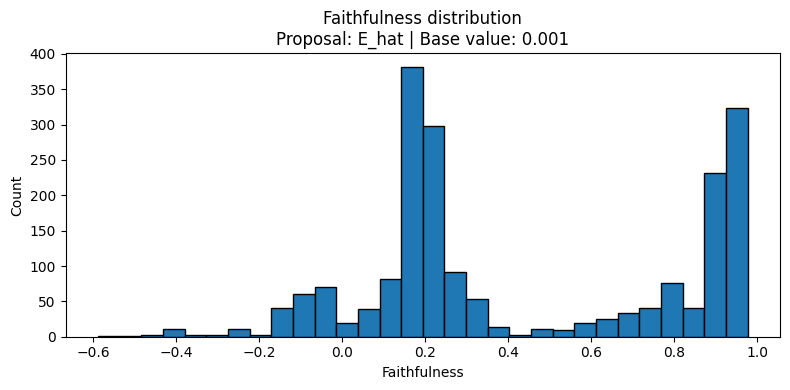

Mean faithfulness: 0.4337 ± 0.3824


In [15]:
import matplotlib.pyplot as plt

# Pick one combination to plot — change these as needed
plot_base_value = 0.001
plot_prop = 'E_hat'

faith_values = fixed_faith_dict[plot_base_value][plot_prop]

plt.figure(figsize=(8, 4))
plt.hist(faith_values, bins=30, edgecolor='black')
plt.title(f'Faithfulness distribution\nProposal: {plot_prop} | Base value: {plot_base_value}')
plt.xlabel('Faithfulness')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

print(f'Mean faithfulness: {faith_values.mean():.4f} ± {faith_values.std():.4f}')